*Pair ids renumbered by stage on 2026-10-29 (X4 → X5, X5 → X9, X6 → X8; see `bench/configs/series.yaml`). The source uses the new ids; stored outputs still show the old ones.*

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

# What helps and what hurts a cross-species alignment: one cost at a time, in 2D

The volume pipeline (`volume_align_demo.ipynb`) aligns human and mouse embryos with one fused GW solve. That solve mixes two sources of information: **space** (distances within each embryo) and **features** (the shared ortholog embedding). This notebook asks which of the two helps and which hurts. It does so on **real 2D sections**, which removes every stage-1 uncertainty (stacking, z gaps, field, volume sampling, the way back to the spots). The 3D version follows once these results are in.

Each section is aligned with one fixed partner of the other species: the section with the closest laterality L. The partner is chosen without labels and is the same for every run. Only the cost changes:

| run | within each section | between the sections | answers |
|---|---|---|---|
| `s-euc_f-euc` | Euclidean distances | features | the reference (the cost of the benchmark's `sec2sec_s-euc_f-euc_bal`, α = 0.5) |
| `s-euc_f-none` | Euclidean distances | none | how much space alone gets |
| `s-eucα_f-lab` | Euclidean distances | organ labels | a ceiling, and how far the geometry pulls away from the labels as α grows |
| `s-none_f-euc` | none | features | how much the features alone get (plain Wasserstein) |

For FGW the parameter α describes the weight of the GW term. 
Every run is solved balanced (τ = 1, as in `sec2sec_s-euc_f-euc_bal`) and unbalanced (τ = 0.95, so tissue without a counterpart can stay unmatched).

**Run names.** The runs follow `sides_space_features_marginals` (`docs/cross_species_alignment_results.md`, "Run names"). Every run here has the sides `sec2part` (the laterality partner section). In the main ablation the `run` column holds the space and features slots and the `tau` column the marginals (1: `bal`, 0.95: `ub`), so `s-euc_f-euc` at τ = 1 is `sec2part_s-euc_f-euc_bal`. In the follow-ups, `kind` is the sides slot (`sec2part`, `sec2emb`) and `run` the rest.

*The outputs below are from the run of 2026-10-23 and still show the old labels:* `fgw` = `s-euc_f-euc`, `gw` = `s-euc_f-none`, `label_fgw@α` = `s-eucα_f-lab` (α = 0.5: `s-euc_f-lab`), `w` = `s-none_f-euc`; in the follow-ups `fgw@α` = `s-eucα_f-euc_bal`, `w` = `s-none_f-euc_bal`, `w_semi@τ_b` = `s-none_f-euc_semiτ_b`, `w_nn` = `s-none_f-euc_nn`, `label_w` = `s-none_f-lab_bal`, `label_nn` = `s-none_f-lab_nn`, kind `partner section` = `sec2part`, `whole embryo` = `sec2emb`; `A_fgw` = `sec2sec_s-euc_f-euc_bal`, `PC_fgw` = `pts2pts_s-euc_f-euc_ub`.

**Two scores** for every query section, in both directions:
- **κ_bal**, the benchmark's metric. It is circular for `s-euc*_f-lab`, which sees the labels it is scored on, so read that run as a ceiling.
- **gene r**, the mean Pearson r of the 500 held-out ortholog genes (never in the embedding) between each query spot and what P transports to it, minus the same with the target's spots shuffled. No run sees these genes, so this score is fair for all of them.

**What to keep in mind:**
- **Depth.** Partner sections can still be cut at different mediolateral positions, so organs go missing on one side. This hurts `s-euc_f-none` most.
- **Mirror images.** GW cannot tell a section from its mirror image. The `flip` column marks couplings whose best rigid map is a reflection when `s-euc_f-euc`'s is not, or the reverse.
- **No neighbourhoods for `s-none_f-euc`.** It matches by cell type, and the species batch effect stays in the features.
- **τ means different things for different costs.** The unbalanced runs weigh the same τ against costs on different scales, so they reject different amounts of mass (`matched`). The balanced runs are the clean comparison.

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIR = "X5"                      # a cross pair of bench/configs/series.yaml (a = human, b = mouse)
SEED = 0
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
PIPELINE = "sec2sec_s-euc_f-euc_bal"  # the 2D pipeline whose data and FGW settings are used
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
ALPHAS_LABEL = (0.5, 0.9, 0.99)  # GW weights of the label runs s-euc*_f-lab (alpha = 1: s-euc_f-none)
TAUS = (1.0, 0.95)               # marginal relaxation: 1 balanced, < 1 unbalanced
SHOW_SECTIONS = None             # human sections in figure 3; None: all

In [3]:
# Parameters
PAIR = "X5"
SEED = 0


In [4]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn

from mgw import crossspecies as cs
from mgw import stack3d as s3
from mgw.bench import config, metrics, prepare, series, solvers, store, volume
from mgw.bench.pipelines.common import Task
from mgw.bench.report.figures import OTHER, organ_palette

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
pair = series.load(cfg.series_path()).pairs[PAIR]
task = Task(cfg, PIPELINE, pair, SEED, root)
H, Mo = task.data["a"], task.data["b"]           # {name: Section}: human, mouse
print(f"pair {pair.id}: {pair.a.name} (human, {len(H)} sections) <-> {pair.b.name} (mouse, {len(Mo)} sections)")
print(f"root {root}\nFGW settings: {task.fgw}")

pair X4: CS18_E1 (human, 6 sections) <-> E12.5_E1 (mouse, 5 sections)
root /nas/lnt/ga79jin/MGW/data/bench
FGW settings: FGWParams(alpha=0.5, epsilon=0.005, inner_maxit=3000, outer_maxit=200, inner_tol=1e-07, outer_tol=1e-07)


## The partners

Every section is aligned with the section of the other embryo whose laterality L is closest (as the laterality partner in `bench/placement.py`). Direction `b_stack` has the human sections as queries, `a_stack` the mouse sections. A pair of sections that serves both directions is solved once; the mouse queries use the transpose of its coupling.

In [5]:
def partner(q, targets):
    ok = {n: t.L for n, t in targets.items() if np.isfinite(t.L)}
    return min(ok, key=lambda n: abs(ok[n] - q.L)) if np.isfinite(q.L) and ok else None


queries = [("b_stack", q, partner(H[q], Mo)) for q in H] + [("a_stack", q, partner(Mo[q], H)) for q in Mo]
queries = [(d, q, t) for d, q, t in queries if t is not None]
pairs = sorted({(q, t) if d == "b_stack" else (t, q) for d, q, t in queries})   # (human, mouse)
print(pd.DataFrame([dict(direction=d, query=q, L_query=(H if d == "b_stack" else Mo)[q].L, partner=t,
                         L_partner=(Mo if d == "b_stack" else H)[t].L) for d, q, t in queries]).round(3)
      .to_string(index=False))
print(f"\n{len(pairs)} pairs of sections to solve")

direction      query  L_query    partner  L_partner
  b_stack  CS18_E1S1    0.326 E12.5_E1S3      0.103
  b_stack  CS18_E1S2    0.560 E12.5_E1S5      0.667
  b_stack  CS18_E1S3    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S4    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S5    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S6    0.667 E12.5_E1S5      0.667
  a_stack E12.5_E1S1    0.765  CS18_E1S6      0.667
  a_stack E12.5_E1S2    0.808  CS18_E1S6      0.667
  a_stack E12.5_E1S3    0.103  CS18_E1S1      0.326
  a_stack E12.5_E1S4    0.752  CS18_E1S6      0.667
  a_stack E12.5_E1S5    0.667  CS18_E1S6      0.667

9 pairs of sections to solve


## The costs and the solvers

- **Space:** max-normalized Euclidean distances within each section (centred, RMS radius 1), as in `pipelines/real2d.py`.
- **Features:** the benchmark's cross cost `task.cross_cost` (distances in the ortholog embedding over one scale per pair).
- **Labels:** the cost between two spots is 0 for the same organ, 1 for different organs, and 0.5 when either is `Other` or `Excluded` (no evidence either way), averaged over the organ compositions of the two spots.

`s-euc_f-none` and `s-euc*_f-lab` use the benchmark's FGW solver (`solvers.fgw`), with α the weight of the GW term. `s-none_f-euc` uses entropic OT on the feature cost alone, with OTT's Sinkhorn at the same ε (`solvers.fgw` cannot do α = 0).

In [6]:
def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot_linear(M, tau, p):
    """Entropic OT on the cross cost alone (unbalanced for tau < 1), uniform masses."""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=p.epsilon)
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, tau_a=tau, tau_b=tau))
    return np.asarray(out.matrix, dtype=np.float64), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


# run: the space and features slots of the name (sides: sec2part; marginals: the solve's tau, 1 bal, 0.95 ub)
# -> (cross cost, alpha = weight of the GW term; 0: Wasserstein only)
s_euc = lambda a: "s-euc" if a == 0.5 else f"s-euc{a:g}"   # the space slot: GW on Euclidean distances, weight a
RUNS = {"s-euc_f-euc": ("features", 0.5), "s-euc_f-none": (None, 1.0),
        **{f"{s_euc(a)}_f-lab": ("labels", a) for a in ALPHAS_LABEL}, "s-none_f-euc": ("features", 0.0)}


def solve(run, h, m, tau):
    cross, alpha = RUNS[run]
    M = task.cross_cost(h.emb, m.emb) if cross == "features" else label_cost(h.comp, m.comp) if cross else None
    if alpha == 0:
        return ot_linear(M, tau, task.fgw)
    return solvers.fgw(None, None, M, dataclasses.replace(task.fgw, alpha=alpha), Ca=D[h.name], Cb=D[m.name],
                       tau_a=tau, tau_b=tau)


# the label cost on toy spots: heart, heart, brain, Other
toy = metrics.onehot(["Heart", "Heart", "Brain", "Other"])
assert np.allclose(label_cost(toy, toy), [[0, 0, 1, .5], [0, 0, 1, .5], [1, 1, 0, .5], [.5, .5, .5, .5]])
# Wasserstein: balanced marginals are uniform
Pt, _ = ot_linear(np.random.default_rng(0).random((30, 20)), 1.0, task.fgw)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4) and np.allclose(Pt.sum(0), 1 / 20, atol=1e-4)
print("toy checks passed; runs:", ", ".join(RUNS))

toy checks passed; runs: fgw, gw, label_fgw@0.5, label_fgw@0.9, label_fgw@0.99, w


## Solve and score

For every pair of sections, run and τ, P is scored right away for each query section it serves:
- **κ_bal** (`task.score`, exactly as in the benchmark; K counts the organs of the whole target embryo);
- **gene r**, the held-out genes through P (`crossspecies.coexpression`), mean r minus the shuffled mean r;
- **matched**, the mass P transports (1 when balanced);
- **flip**, whether the rigid map fitted to P (`stack3d.procrustes`) is a reflection when that of balanced `s-euc_f-euc` is not, or the reverse.

Only the couplings that figure 3 draws are kept (all of them would take tens of GB).

In [7]:
SHOW_RUNS = ["s-euc_f-euc", "s-euc_f-none", f"{s_euc(0.9 if 0.9 in ALPHAS_LABEL else ALPHAS_LABEL[0])}_f-lab",
             "s-none_f-euc"]
secs = {**H, **Mo}
D = {n: solvers.dist_norm(task.xy(secs[n])) for n in sorted({n for p in pairs for n in p})}
serves = {p: [(d, q, t) for d, q, t in queries if p == ((q, t) if d == "b_stack" else (t, q))] for p in pairs}

kept, solves, rows = {}, [], []
for h, m in pairs:
    t0 = time.perf_counter()
    for run in RUNS:
        for tau in TAUS:
            Phm, info = solve(run, H[h], Mo[m], tau)
            if not np.isfinite(Phm).all():
                raise FloatingPointError(f"{run} tau {tau}: non-finite coupling for {h} x {m}")
            solves.append(dict(run=run, tau=tau, human=h, mouse=m, mass=Phm.sum(), seconds=info.get("seconds"),
                               converged=info.get("converged")))
            if run in SHOW_RUNS and tau == 1.0:
                kept[run, h, m] = Phm.astype(np.float32)
            for d, qn, tn in serves[h, m]:
                q, t, Pq = (H[qn], Mo[tn], Phm) if d == "b_stack" else (Mo[qn], H[tn], Phm.T)
                r, r0 = cs.coexpression(Pq, q.Y, t.Y, seed=SEED)
                R, _ = s3.procrustes([(task.xy(q), task.xy(t), Pq)])
                rows.append(dict(run=run, tau=tau, direction=d, query=qn, target=tn,
                                 kappa_bal=task.score(d, q, t.name, t.comp, Pq, keep=False)["kappa_bal"],
                                 gene_r=np.nanmean(r) - np.nanmean(r0), matched=Pq.sum(),
                                 reflection=np.linalg.det(R) < 0))
    print(f"{h} ({H[h].n}) x {m} ({Mo[m].n}): {len(RUNS) * len(TAUS)} solves, {time.perf_counter() - t0:.0f} s")

solves = pd.DataFrame(solves)
print("\nmean transported mass and seconds per solve:")
print(solves.groupby(["run", "tau"], sort=False)[["mass", "seconds"]].mean().round(3).unstack("tau").to_string())
if not solves.converged.astype(bool).all():
    print("\nnot converged:", solves.loc[~solves.converged.astype(bool), ["run", "tau", "human", "mouse"]]
          .to_string(index=False))

CS18_E1S1 (5000) x E12.5_E1S3 (5000): 12 solves, 1740 s


CS18_E1S2 (5000) x E12.5_E1S5 (5000): 12 solves, 2069 s


CS18_E1S3 (5000) x E12.5_E1S5 (5000): 12 solves, 1128 s


CS18_E1S4 (5000) x E12.5_E1S5 (5000): 12 solves, 1699 s


CS18_E1S5 (5000) x E12.5_E1S5 (5000): 12 solves, 1427 s


CS18_E1S6 (4999) x E12.5_E1S1 (5000): 12 solves, 2058 s


CS18_E1S6 (4999) x E12.5_E1S2 (5000): 12 solves, 1369 s


CS18_E1S6 (4999) x E12.5_E1S4 (5000): 12 solves, 1676 s


CS18_E1S6 (4999) x E12.5_E1S5 (5000): 12 solves, 1764 s

mean transported mass and seconds per solve:
               mass        seconds         
tau            1.00   0.95    1.00     0.95
run                                        
fgw             1.0  0.284  56.276   47.481
gw              1.0  1.447  56.125  510.442
label_fgw@0.5   1.0  0.755  61.490   84.786
label_fgw@0.9   1.0  1.284  66.388  357.192
label_fgw@0.99  1.0  1.430  56.038  350.599
w               1.0  0.305   3.158    4.039

not converged:            run  tau     human      mouse
           fgw 1.00 CS18_E1S1 E12.5_E1S3
           fgw 0.95 CS18_E1S1 E12.5_E1S3
            gw 1.00 CS18_E1S1 E12.5_E1S3
            gw 0.95 CS18_E1S1 E12.5_E1S3
 label_fgw@0.5 1.00 CS18_E1S1 E12.5_E1S3
 label_fgw@0.5 0.95 CS18_E1S1 E12.5_E1S3
 label_fgw@0.9 1.00 CS18_E1S1 E12.5_E1S3
 label_fgw@0.9 0.95 CS18_E1S1 E12.5_E1S3
label_fgw@0.99 1.00 CS18_E1S1 E12.5_E1S3
label_fgw@0.99 0.95 CS18_E1S1 E12.5_E1S3
             w 1.00 CS18_E1S1 E12.5

In [8]:
scores = pd.DataFrame(rows)
ref = scores[(scores.run == "s-euc_f-euc") & (scores.tau == 1.0)].set_index(["direction", "query"]).reflection
scores["flip"] = scores.reflection.to_numpy() != ref.loc[list(zip(scores.direction, scores["query"]))].to_numpy()

summary = (scores.groupby(["run", "tau"], sort=False)
           .agg(kappa_bal=("kappa_bal", "mean"), gene_r=("gene_r", "mean"), matched=("matched", "mean"),
                flips=("flip", "sum"), n=("query", "size")))
print(summary.round(3).to_string())

# the reference against the benchmark: balanced s-euc_f-euc should reproduce PIPELINE's candidate rows of the
# same pairs
bench = store.result_dir(root, cfg, PIPELINE, pair.id, SEED) / "scores.csv"
if bench.exists():
    b = pd.read_csv(bench).query("role == 'candidate'").set_index(["direction", "query", "target"]).kappa_bal
    ours = scores[(scores.run == "s-euc_f-euc") & (scores.tau == 1.0)].set_index(["direction", "query", "target"]).kappa_bal
    both = pd.concat([ours.rename("here"), b.rename(PIPELINE)], axis=1, join="inner")
    print(f"\ns-euc_f-euc (balanced) vs {PIPELINE} on {len(both)} shared rows: "
          f"max |difference| in kappa_bal {np.abs(both.here - both[PIPELINE]).max():.4f}")
else:
    print(f"\nno {PIPELINE} results at {bench}; the reference check is skipped")

                     kappa_bal  gene_r  matched  flips   n
run            tau                                        
fgw            1.00      0.293   0.350    1.000      0  11
               0.95      0.343   0.373    0.287      0  11
gw             1.00     -0.021  -0.028    1.000      6  11
               0.95     -0.021  -0.027    1.447      6  11
label_fgw@0.5  1.00      0.500   0.245    1.000      1  11
               0.95      0.614   0.276    0.751      0  11
label_fgw@0.9  1.00      0.467   0.237    1.000      1  11
               0.95      0.517   0.264    1.281      3  11
label_fgw@0.99 1.00      0.171   0.164    1.000      1  11
               0.95      0.161   0.164    1.430      3  11
w              1.00      0.295   0.361    1.000      0  11
               0.95      0.340   0.372    0.309      0  11

fgw (balanced) vs A_fgw on 11 shared rows: max |difference| in kappa_bal 0.0000


## Figure 1: every run against the reference

Large markers show the mean over the query sections of both directions; small dots show single sections. The dashed line marks balanced `s-euc_f-euc`. Better is to the right in both panels.

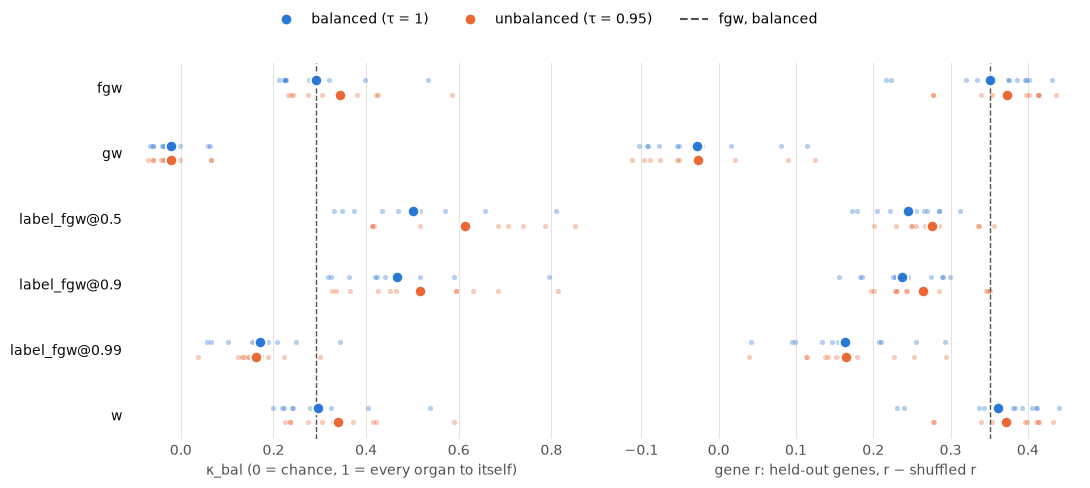

In [9]:
BAL, UNB = "#2a78d6", "#eb6834"                   # categorical slots 1 and 2 (validated pair)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
tau_color = {TAUS[0]: BAL, **({TAUS[1]: UNB} if len(TAUS) > 1 else {})}
tau_name = lambda tau: "bal (τ = 1)" if tau == 1 else f"ub (τ = {tau:g})"
order = list(RUNS)


def style(ax, xlabel):
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(order) + 1.6), sharey=True)
for ax, col, xlabel in ((axes[0], "kappa_bal", "κ_bal (0 = chance, 1 = every organ to itself)"),
                        (axes[1], "gene_r", "gene r: held-out genes, r − shuffled r")):
    for k, tau in enumerate(TAUS):
        off = (k - (len(TAUS) - 1) / 2) * 0.22
        for i, run in enumerate(order):
            v = scores[(scores.run == run) & (scores.tau == tau)][col].to_numpy()
            ax.scatter(v, np.full(len(v), i + off), s=14, color=tau_color[tau], alpha=0.35, linewidths=0)
            ax.scatter([np.nanmean(v)], [i + off], s=70, color=tau_color[tau], edgecolors="white", linewidths=1.5,
                       zorder=3)
    ax.axvline(summary.loc[("s-euc_f-euc", 1.0), col], color=MUTED, ls="--", lw=1)
    style(ax, xlabel)
axes[0].set_yticks(range(len(order)), order, color=INK)
axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=tau_color[t], label=tau_name(t)) for t in TAUS]
           + [Line2D([], [], ls="--", color=MUTED, label="s-euc_f-euc, bal")],
           loc="upper center", ncol=len(TAUS) + 1, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
plt.show()

## Figure 2: how far the geometry pulls away from the labels

`s-euc*_f-lab` from α = 0.5 (half labels) up to α = 1, where it becomes `s-euc_f-none` (no labels). If κ_bal stays high as α grows, the geometry of the two species agrees with their organs. If it falls well before α = 1, the shapes disagree with the homology. Gene r shows whether label supervision also helps within the organs. The dashed line is balanced `s-euc_f-euc`.

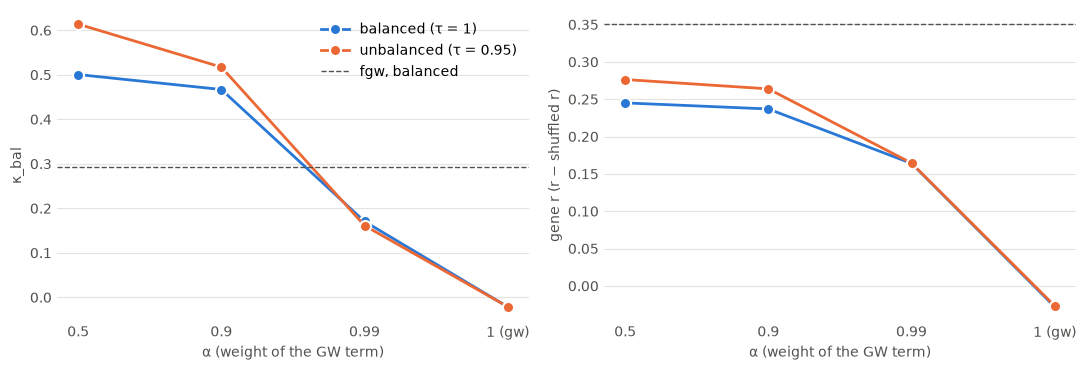

In [10]:
sweep = [f"{s_euc(a)}_f-lab" for a in ALPHAS_LABEL] + ["s-euc_f-none"]
ticks = [f"{a:g}" for a in ALPHAS_LABEL] + ["1 (s-euc_f-none)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, ylabel in ((axes[0], "kappa_bal", "κ_bal"), (axes[1], "gene_r", "gene r (r − shuffled r)")):
    for tau in TAUS:
        y = [summary.loc[(run, tau), col] for run in sweep]
        ax.plot(range(len(sweep)), y, color=tau_color[tau], lw=2, marker="o", ms=8, mec="white", mew=1.5,
                label=tau_name(tau))
    ax.axhline(summary.loc[("s-euc_f-euc", 1.0), col], color=MUTED, ls="--", lw=1, label="s-euc_f-euc, bal")
    ax.set_xticks(range(len(sweep)), ticks)
    ax.set_xlabel("α (weight of the GW term)", color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## Figure 3: the organs each run transfers

One row per human section, all balanced. From left to right:
1. the annotation of its mouse partner, where the labels come from;
2. the annotation of the human section;
3. the organs transferred along each coupling (arg-max, `metrics.hard_prediction`).

The eight most frequent organs of the pair have their own colours; the rest are "Other".

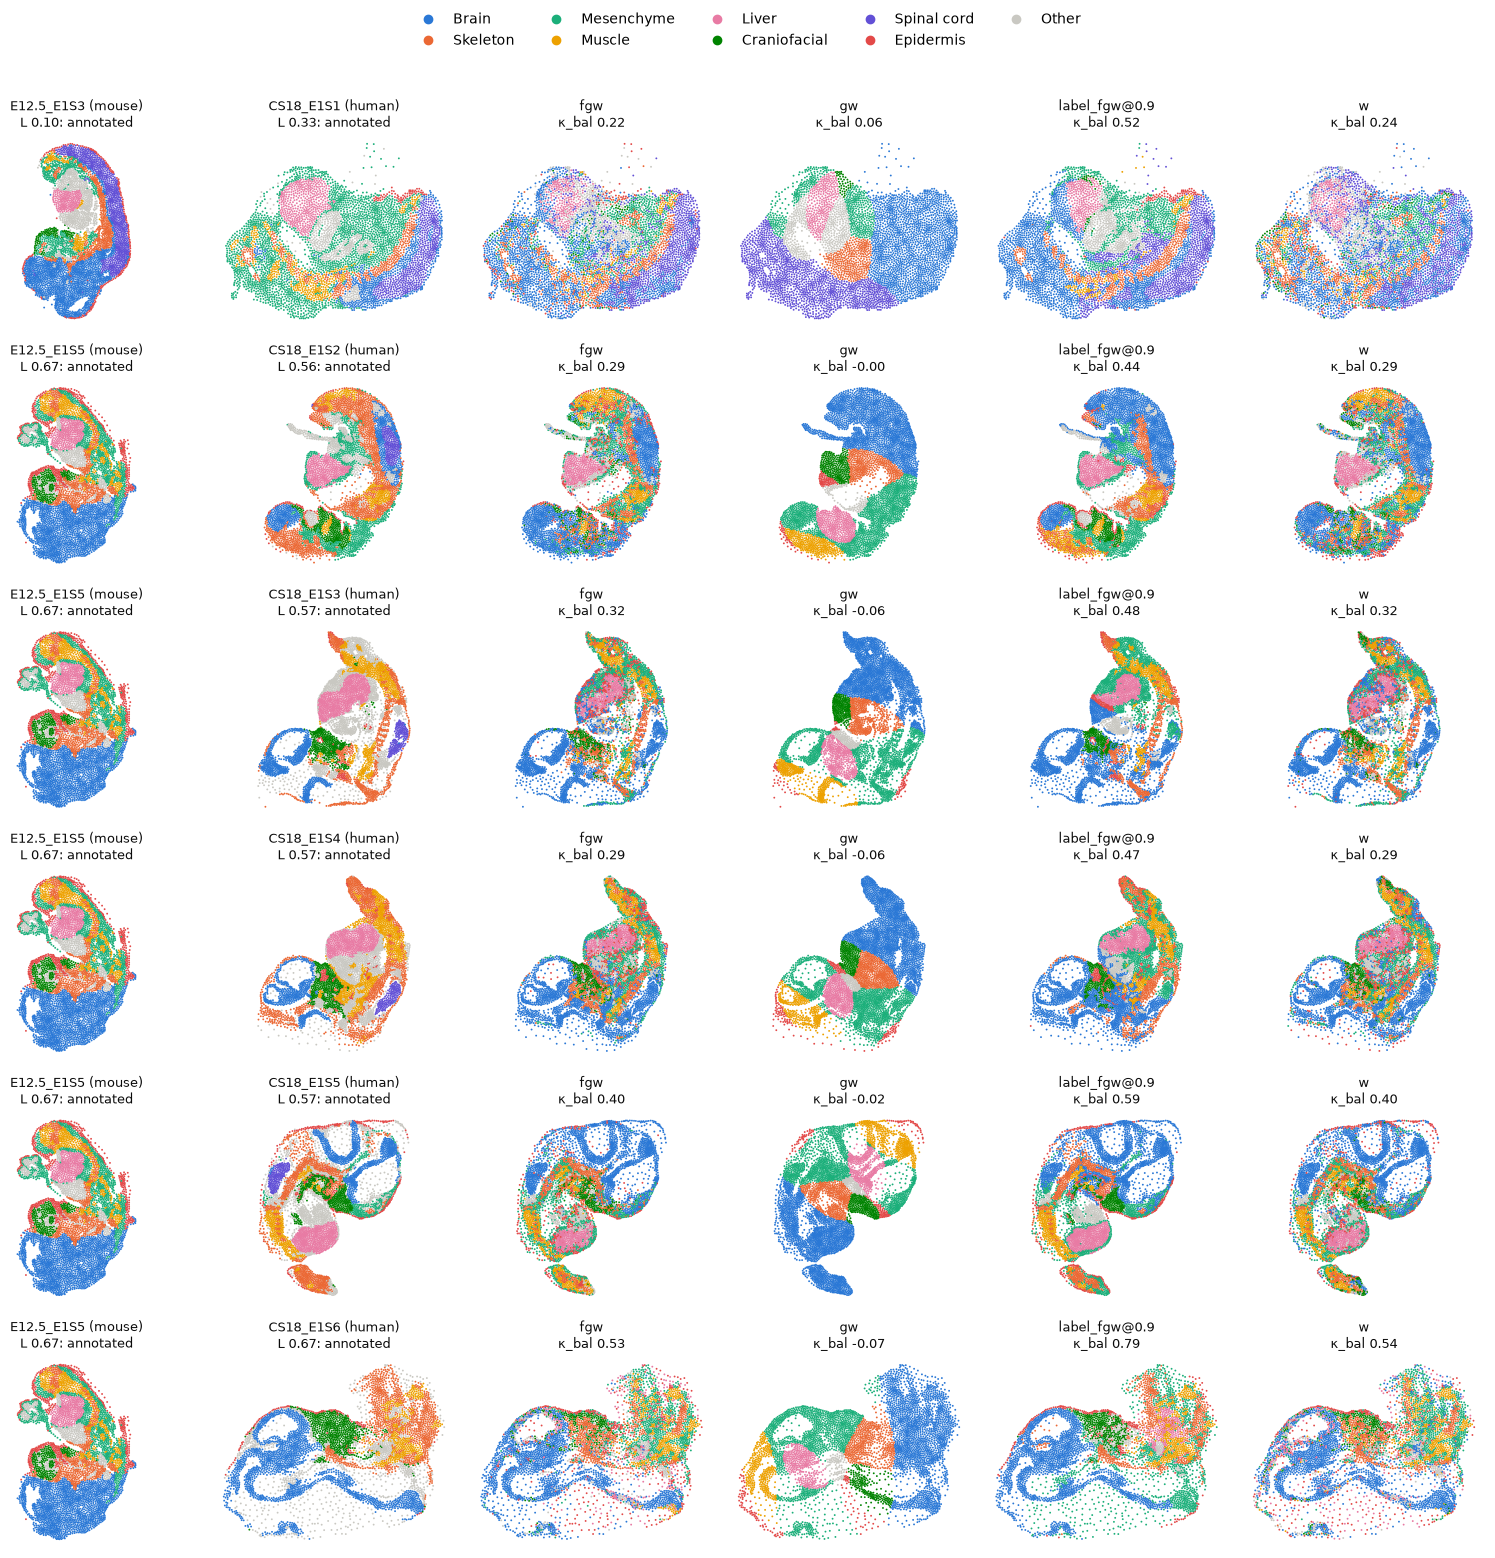

In [11]:
rows3 = [(q, t) for d, q, t in queries if d == "b_stack" and (SHOW_SECTIONS is None or q in SHOW_SECTIONS)]
pal = organ_palette([np.concatenate([s.label for s in H.values()]), np.concatenate([s.label for s in Mo.values()])])
colors = lambda labels: [pal.get(l, OTHER) for l in np.asarray(labels, dtype=str)]
kb = scores[(scores.direction == "b_stack") & (scores.tau == 1.0)].set_index(["run", "query"]).kappa_bal

ncol = 2 + len(SHOW_RUNS)
fig, axes = plt.subplots(len(rows3), ncol, figsize=(2.6 * ncol, 2.6 * len(rows3)), squeeze=False)
for (qn, tn), ax in zip(rows3, axes):
    q, t = H[qn], Mo[tn]
    panels = [(t.xy, t.label, f"{tn} (mouse)\nL {t.L:.2f}: annotated"),
              (q.xy, q.label, f"{qn} (human)\nL {q.L:.2f}: annotated")]
    for run in SHOW_RUNS:
        pred = np.asarray(metrics.ORGANS)[metrics.hard_prediction(kept[run, qn, tn], t.comp)]
        panels.append((q.xy, pred, f"{run}\nκ_bal {kb[run, qn]:.2f}"))
    for a, (xy, lab, title) in zip(ax, panels):
        a.scatter(*np.asarray(xy).T, s=float(np.clip(9000 / len(xy), 1, 12)), c=colors(lab), linewidths=0)
        a.set_aspect("equal"); a.axis("off"); a.set_title(title, fontsize=9, color=INK)
handles = [Line2D([], [], marker="o", ls="", color=c, label=o) for o, c in pal.items()]
handles.append(Line2D([], [], marker="o", ls="", color=OTHER, label="Other"))
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / fig.get_figheight()))
plt.show()

## Per-section table

In [12]:
wide = scores.pivot_table(index=["direction", "query", "target"], columns=["run", "tau"],
                          values=["kappa_bal", "gene_r"]).round(3)
print(wide.to_string())

                                gene_r                                                                                                    kappa_bal                                                                                                   
run                                fgw            gw        label_fgw@0.5        label_fgw@0.9        label_fgw@0.99             w              fgw            gw        label_fgw@0.5        label_fgw@0.9        label_fgw@0.99             w       
tau                               0.95   1.00   0.95   1.00          0.95   1.00          0.95   1.00           0.95   1.00   0.95   1.00      0.95   1.00   0.95   1.00          0.95   1.00          0.95   1.00           0.95   1.00   0.95   1.00
direction query      target                                                                                                                                                                                                                           
a_stack   E1

## How to read the results

- **`s-euc_f-none` against `s-euc_f-euc`:** what the features add to space. If `s-euc_f-none` is near `s-euc_f-euc`, the features contribute little. If `s-euc_f-none` has many `flips`, the mirror ambiguity is part of what hurts space alone.
- **`s-none_f-euc` against `s-euc_f-euc`:** what space adds to the features. If `s-none_f-euc` is close or better, the GW term mostly constrains (or fights) the match.
- **The α curve of `s-euc*_f-lab`:** κ_bal at α = 0.5 is close to the ceiling by construction. Where the curve starts to fall shows how strongly the geometry of the two species disagrees with their organs.
- **Gene r of `s-euc*_f-lab` against `s-euc_f-euc`:** whether knowing the organs also improves the match *within* organs, the part κ_bal cannot see.
- **Balanced against unbalanced:** how much of the damage comes from tissue without a counterpart (depth mismatch). Read the gaps together with `matched`.